# GTSRB training

Trains the sign classifier used by the app and exports it as `traffic_sign_model.tflite`.

Input is a 30x30 RGB image with raw 0-255 values (scaling is done inside the model), output is 43 classes in the same order as `app/src/main/assets/labels.txt`.

Runs locally (`pip install -r requirements.txt`) or on Kaggle. On Kaggle, add the GTSRB dataset with **Add Input** and turn on a GPU; the trained model ends up in the Output tab.

In [1]:
import os
import numpy as np
import pandas as pd
import tensorflow as tf
from PIL import Image
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

IMG_SIZE = 30
NUM_CLASSES = 43
print(tf.__version__)

2.21.0


## Data

On Kaggle the attached dataset under `/kaggle/input` is used. Locally it's downloaded with `kagglehub` (might ask you to log in).

In [2]:
import glob

found = glob.glob("/kaggle/input/**/Train.csv", recursive=True)
if found:
    DATA_DIR = os.path.dirname(found[0])
else:
    import kagglehub
    DATA_DIR = kagglehub.dataset_download("meowmeowmeowmeowmeow/gtsrb-german-traffic-sign")
print(DATA_DIR)
print(os.listdir(DATA_DIR))

Using Colab cache for faster access to the 'gtsrb-german-traffic-sign' dataset.
/kaggle/input/gtsrb-german-traffic-sign
['Meta', 'meta', 'Meta.csv', 'Train.csv', 'Test.csv', 'Test', 'test', 'Train', 'train']


Crop each image to its ROI box and resize to 30x30.

In [3]:
def load_split(csv_name):
    df = pd.read_csv(os.path.join(DATA_DIR, csv_name))
    images = np.empty((len(df), IMG_SIZE, IMG_SIZE, 3), dtype=np.float32)
    for i, row in enumerate(df.itertuples()):
        img = Image.open(os.path.join(DATA_DIR, row.Path)).convert("RGB")
        img = img.crop((row._3, row._4, row._5, row._6))  # Roi.X1, Roi.Y1, Roi.X2, Roi.Y2
        images[i] = np.asarray(img.resize((IMG_SIZE, IMG_SIZE), Image.BILINEAR), dtype=np.float32)
    return images, df["ClassId"].to_numpy()

X, y = load_split("Train.csv")
X_test, y_test = load_split("Test.csv")
X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)
print(X_train.shape, X_val.shape, X_test.shape)

(31367, 30, 30, 3) (7842, 30, 30, 3) (12630, 30, 30, 3)


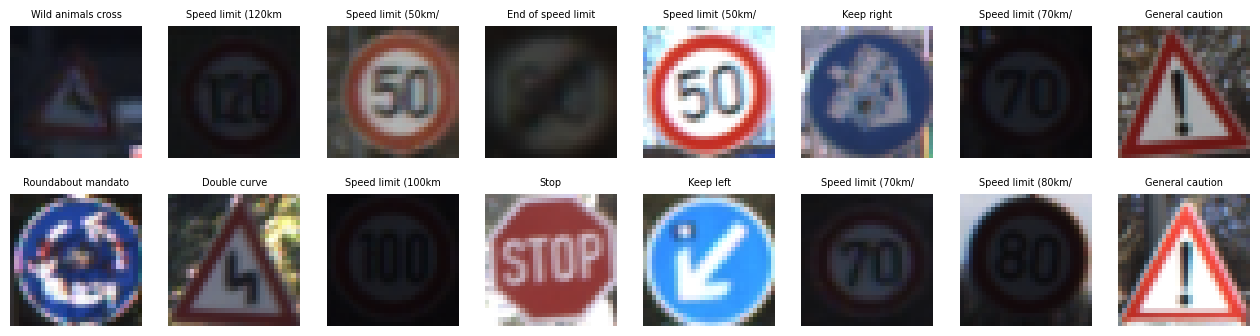

In [4]:
LABELS = [
    "Speed limit (20km/h)",
    "Speed limit (30km/h)",
    "Speed limit (50km/h)",
    "Speed limit (60km/h)",
    "Speed limit (70km/h)",
    "Speed limit (80km/h)",
    "End of speed limit (80km/h)",
    "Speed limit (100km/h)",
    "Speed limit (120km/h)",
    "No passing",
    "No passing for vehicles over 3.5 metric tons",
    "Right-of-way at the next intersection",
    "Priority road",
    "Yield",
    "Stop",
    "No vehicles",
    "Vehicles over 3.5 metric tons prohibited",
    "No entry",
    "General caution",
    "Dangerous curve to the left",
    "Dangerous curve to the right",
    "Double curve",
    "Bumpy road",
    "Slippery road",
    "Road narrows on the right",
    "Road work",
    "Traffic signals",
    "Pedestrians",
    "Children crossing",
    "Bicycles crossing",
    "Beware of ice/snow",
    "Wild animals crossing",
    "End of all speed and passing limits",
    "Turn right ahead",
    "Turn left ahead",
    "Ahead only",
    "Go straight or right",
    "Go straight or left",
    "Keep right",
    "Keep left",
    "Roundabout mandatory",
    "End of no passing",
    "End of no passing by vehicles over 3.5 metric tons",
]

fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for ax, i in zip(axes.flat, np.random.choice(len(X_train), 16, replace=False)):
    ax.imshow(X_train[i].astype(np.uint8)); ax.set_title(LABELS[y_train[i]][:18], fontsize=7); ax.axis("off")
plt.show()

## Model

In [5]:
model = tf.keras.Sequential([
    tf.keras.Input((IMG_SIZE, IMG_SIZE, 3)),
    tf.keras.layers.Rescaling(1.0 / 255),
    tf.keras.layers.RandomRotation(0.05),
    tf.keras.layers.RandomZoom(0.1),
    tf.keras.layers.RandomContrast(0.2),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(32, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu"),
    tf.keras.layers.MaxPooling2D(),
    tf.keras.layers.Dropout(0.25),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(256, activation="relu"),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(NUM_CLASSES, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 30, 30, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 30, 30, 3)      │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 30, 30, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_contrast                 │ (None, 30, 30, 3)      │             0 │
│ (RandomContrast)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 30, 30, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 30, 30, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 15, 15, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 15, 15, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 15, 15, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 3136)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       803,072 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 43)             │        11,051 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 880,075 (3.36 MB)

 Trainable params: 879,883 (3.36 MB)

 Non-trainable params: 192 (768.00 B)

## Train

Epoch 1/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 16s 15ms/step - accuracy: 0.4206 - loss: 1.9920 - val_accuracy: 0.8263 - val_loss: 0.8046
Epoch 2/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 13s 14ms/step - accuracy: 0.7126 - loss: 0.8459 - val_accuracy: 0.9570 - val_loss: 0.1849
Epoch 3/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.8383 - loss: 0.4778 - val_accuracy: 0.9665 - val_loss: 0.1118
Epoch 4/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9080 - loss: 0.2791 - val_accuracy: 0.9878 - val_loss: 0.0552
Epoch 5/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9420 - loss: 0.1844 - val_accuracy: 0.9926 - val_loss: 0.0294
Epoch 6/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9627 - loss: 0.1208 - val_accuracy: 0.9927 - val_loss: 0.0298
Epoch 7/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 7s 14ms/step - accuracy: 0.9706 - loss: 0.0966 - val_accuracy: 0.9913 - val_loss: 0.0342
Epoch 8/20
491/491 ━━━━━━━━━━━━━━━━━━━━ 10s 14ms/step - accuracy: 0.9747 - loss: 0.0835 - val_a

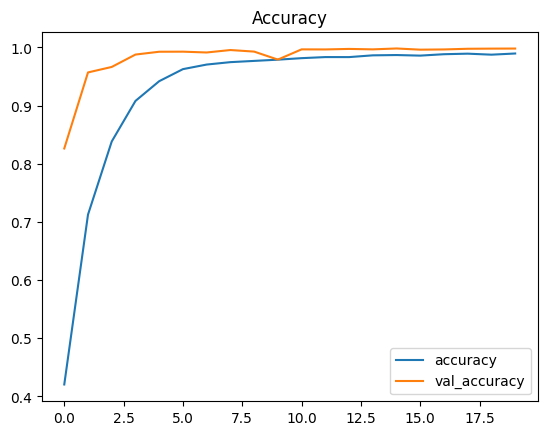

In [6]:
history = model.fit(
    X_train, y_train,
    validation_data=(X_val, y_val),
    epochs=20, batch_size=64,
    callbacks=[tf.keras.callbacks.EarlyStopping(patience=4, restore_best_weights=True)],
)

pd.DataFrame(history.history)[["accuracy", "val_accuracy"]].plot(title="Accuracy"); plt.show()

## Test set

In [7]:
test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
print(f"Test accuracy: {test_acc:.4f}")

Test accuracy: 0.9816


## Export to TFLite

In [8]:
converter = tf.lite.TFLiteConverter.from_keras_model(model)
converter.optimizations = [tf.lite.Optimize.DEFAULT]  # 8-bit weights, ~4x smaller
tflite_model = converter.convert()

# inside the repo: write straight into the app, otherwise (Kaggle) next to the notebook
app_assets = "../app/src/main/assets"
out_dir = app_assets if os.path.isdir(app_assets) else "."
out_path = os.path.join(out_dir, "traffic_sign_model.tflite")
with open(out_path, "wb") as f:
    f.write(tflite_model)
print(f"{out_path}: {len(tflite_model) / 1024:.0f} KB")

Saved artifact at '/tmp/tmp6qfk3xt3'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 30, 30, 3), dtype=tf.float32, name='keras_tensor')
Output Type:
  TensorSpec(shape=(None, 43), dtype=tf.float32, name=None)
Captures:
  132745585639056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585638864: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585886800: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585885456: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585639248: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585628496: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585887184: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585891600: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585891408: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585895056: TensorSpec(shape=(), dtype=tf.resource, name=None)
  132745585889680

Quick check that the exported model gives the same results.

In [9]:
interpreter = tf.lite.Interpreter(model_content=tflite_model)
interpreter.allocate_tensors()
inp, out = interpreter.get_input_details()[0], interpreter.get_output_details()[0]

correct = 0
for img, label in zip(X_test[:1000], y_test[:1000]):
    interpreter.set_tensor(inp["index"], img[None])
    interpreter.invoke()
    correct += int(np.argmax(interpreter.get_tensor(out["index"])) == label)
print(f"TFLite accuracy (first 1000 test images): {correct / 1000:.4f}")

/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


TFLite accuracy (first 1000 test images): 0.9820
